# Regiões e estados

Como as avaliações variam por localização do cliente? Compara estados, regiões e presença de vendedores locais.

In [1]:
import pandas as pd
import numpy as np


In [2]:
from pathlib import Path

# Procura a raiz a partir da pasta atual; funciona também nas cópias em outputs/notebooks.
RAIZ_PROJETO = next(
    (pasta for pasta in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
     if (pasta / 'executar_pipeline.py').is_file() and (pasta / 'src').is_dir()),
    None
)
if RAIZ_PROJETO is None:
    raise FileNotFoundError('Execute o notebook dentro da pasta do projeto ou de uma subpasta.')

CAMINHO_PROCESSADOS = RAIZ_PROJETO / 'data' / 'processed'

df_base = pd.read_parquet(f'{CAMINHO_PROCESSADOS}/base_analitica_pedidos.parquet')
df_itens_pedidos = pd.read_parquet(f'{CAMINHO_PROCESSADOS}/itens_pedidos.parquet')


In [3]:
colunas_regioes = [
    'order_id',
    'customer_id',
    'customer_state',
    'customer_city',
    'valor_total',
    'valor_produtos',
    'valor_frete',
    'pct_frete',
    'review_score',
    'review_ruim',
    'review_neutra',
    'review_boa',
    'pedido_entregue',
    'possui_avaliacao',
    'is_late',
    'delivery_delay_days'
]

colunas_vendedores = [
    'order_id',
    'seller_id',
    'seller_state',
    'seller_city',
]

regioes = {
    'norte': ['AC', 'AP', 'AM', 'PA', 'RO', 'RR', 'TO'],
    'nordeste': ['AL', 'BA', 'CE', 'MA', 'PB', 'PE', 'PI', 'RN', 'SE'],
    'centro_oeste': ['DF', 'GO', 'MT', 'MS'],
    'sudeste': ['ES', 'MG', 'RJ', 'SP'],
    'sul': ['PR', 'RS', 'SC']
}

df_regioes = (
df_base.loc[lambda dados: dados ['pedido_entregue'], colunas_regioes]
.dropna(subset=['review_score', 'is_late'])

.copy()
)
assert df_regioes['order_id'].is_unique

df_regioes.isna().sum()


order_id               0
customer_id            0
customer_state         0
customer_city          0
valor_total            0
valor_produtos         0
valor_frete            0
pct_frete              0
review_score           0
review_ruim            0
review_neutra          0
review_boa             0
pedido_entregue        0
possui_avaliacao       0
is_late                0
delivery_delay_days    0
dtype: int64

In [4]:
df_pedido_vendedor = (
    df_itens_pedidos[colunas_vendedores]
    .drop_duplicates(subset=['order_id', 'seller_id'])
)

df_comparacao_estados = (
    df_base[['order_id', 'customer_state']]
    .merge(
        df_pedido_vendedor,
        on='order_id',
        how='inner',
        validate='one_to_many'
    )
)

df_comparacao_estados['mesmo_estado'] = (
    df_comparacao_estados['customer_state']
    .eq(df_comparacao_estados['seller_state'])
    .astype('boolean')
)


In [5]:
def criar_ranking_geografico(dados, vendedores, coluna_cliente, coluna_vendedor):
    """Ranking por localização; local = pelo menos um vendedor da mesma localização."""
    assert dados['order_id'].is_unique, 'A base deve ter uma linha por pedido.'

    # A comparação pode ter vários vendedores, mas será resumida por pedido.
    comparacao = dados[['order_id', coluna_cliente]].merge(
        vendedores[['order_id', 'seller_id', coluna_vendedor]],
        on='order_id',
        how='left',
        validate='one_to_many'
    )

    comparacao['vendedor_local'] = (
        comparacao[coluna_cliente].eq(comparacao[coluna_vendedor])
        .astype('boolean')
        .mask(
            comparacao[coluna_cliente].isna()
            | comparacao[coluna_vendedor].isna(),
            pd.NA
        )
    )

    por_pedido = comparacao.groupby('order_id').agg(
        possui_vendedor_local=('vendedor_local', 'any'),
        possui_localizacao_ausente=('vendedor_local', lambda valores: valores.isna().any())
    )

    # Sem correspondência e com localização ausente, o resultado é desconhecido.
    por_pedido['possui_vendedor_local'] = (
        por_pedido['possui_vendedor_local'].astype('boolean')
        .mask(
            ~por_pedido['possui_vendedor_local']
            & por_pedido['possui_localizacao_ausente'],
            pd.NA
        )
    )

    base_ranking = dados.copy()
    base_ranking['possui_vendedor_local'] = (
        base_ranking['order_id'].map(por_pedido['possui_vendedor_local'])
    )

    ranking = (
        base_ranking.groupby(coluna_cliente)
        .agg(
            quantidade_pedidos=('order_id', 'nunique'),
            nota_media=('review_score', 'mean'),
            reviews_ruins=('review_ruim', 'sum'),
            reviews_neutras=('review_neutra', 'sum'),
            reviews_boas=('review_boa', 'sum'),
            pct_pedidos_com_vendedor_local=('possui_vendedor_local', 'mean')
        )
        .reset_index()
    )

    for tipo in ('ruins', 'neutras', 'boas'):
        ranking[f'pct_reviews_{tipo}'] = (
            ranking[f'reviews_{tipo}'] / ranking['quantidade_pedidos']
        )

    taxa_geral_reviews_ruins = (
        ranking['reviews_ruins'].sum()
        / ranking['quantidade_pedidos'].sum()
        if ranking['quantidade_pedidos'].sum() else float('nan')
    )

    ranking['diferenca_taxa_geral'] = (
        ranking['pct_reviews_ruins'] - taxa_geral_reviews_ruins
    )
    ranking['comparacao_taxa_geral'] = np.select(
        [
            ranking['diferenca_taxa_geral'].gt(0).to_numpy(dtype=bool),
            ranking['diferenca_taxa_geral'].lt(0).to_numpy(dtype=bool)
        ],
        ['Acima da média', 'Abaixo da média'],
        default='Igual à média'
    )
    ranking['pct_participacao_pedidos'] = (
        ranking['quantidade_pedidos'] / ranking['quantidade_pedidos'].sum()
    )

    ranking = (
        ranking.sort_values(
            ['pct_reviews_ruins', 'quantidade_pedidos'],
            ascending=[False, False]
        )
        .reset_index(drop=True)
    )
    ranking.insert(0, 'posicao', range(1, len(ranking) + 1))

    # Mantém as colunas anteriores na mesma ordem; nova métrica ao final.
    coluna_local = ranking.pop('pct_pedidos_com_vendedor_local')
    ranking['pct_pedidos_com_vendedor_local'] = coluna_local
    return ranking


# Acrescenta as regiões sem alterar os filtros da base de pedidos.
df_regioes['regiao'] = pd.NA
df_pedido_vendedor = df_pedido_vendedor.copy()
df_pedido_vendedor['seller_region'] = pd.NA

for regiao, estados in regioes.items():
    df_regioes.loc[
        df_regioes['customer_state'].isin(estados), 'regiao'
    ] = regiao
    df_pedido_vendedor.loc[
        df_pedido_vendedor['seller_state'].isin(estados), 'seller_region'
    ] = regiao

formatacao_ranking = {
    'nota_media': '{:.2f}',
    'pct_reviews_ruins': '{:.2%}',
    'pct_reviews_neutras': '{:.2%}',
    'pct_reviews_boas': '{:.2%}',
    'diferenca_taxa_geral': '{:+.2%}',
    'pct_participacao_pedidos': '{:.2%}',
    'pct_pedidos_com_vendedor_local': '{:.2%}'
}


In [6]:
df_ranking_estados = criar_ranking_geografico(
    df_regioes,
    df_pedido_vendedor,
    coluna_cliente='customer_state',
    coluna_vendedor='seller_state'
)

display(df_ranking_estados.style.format(formatacao_ranking, na_rep='Sem informação'))
print('Estados analisados:', len(df_ranking_estados))


,posicao,customer_state,quantidade_pedidos,nota_media,reviews_ruins,reviews_neutras,reviews_boas,pct_reviews_ruins,pct_reviews_neutras,pct_reviews_boas,diferenca_taxa_geral,comparacao_taxa_geral,pct_participacao_pedidos,pct_pedidos_com_vendedor_local
0,1,AL,396,3.84,86,28,282,21.72%,7.07%,71.21%,+8.62%,Acima da média,0.41%,0.00%
1,2,MA,711,3.81,147,70,494,20.68%,9.85%,69.48%,+7.58%,Acima da média,0.74%,1.97%
2,3,SE,332,3.89,64,29,239,19.28%,8.73%,71.99%,+6.18%,Acima da média,0.35%,0.00%
3,4,RJ,12272,3.95,2288,1024,8960,18.64%,8.34%,73.01%,+5.55%,Acima da média,12.79%,7.81%
4,5,PA,937,3.89,174,92,671,18.57%,9.82%,71.61%,+5.47%,Acima da média,0.98%,0.00%
5,6,BA,3237,3.91,570,323,2344,17.61%,9.98%,72.41%,+4.51%,Acima da média,3.37%,2.04%
6,7,CE,1277,3.94,222,128,927,17.38%,10.02%,72.59%,+4.29%,Acima da média,1.33%,0.70%
7,8,PI,474,3.97,79,41,354,16.67%,8.65%,74.68%,+3.57%,Acima da média,0.49%,0.21%
8,9,PB,515,4.06,79,47,389,15.34%,9.13%,75.53%,+2.24%,Acima da média,0.54%,0.19%
9,10,PE,1588,4.07,242,127,1219,15.24%,8.00%,76.76%,+2.14%,Acima da média,1.66%,1.45%


Estados analisados: 27


In [7]:
df_ranking_regioes = criar_ranking_geografico(
    df_regioes,
    df_pedido_vendedor,
    coluna_cliente='regiao',
    coluna_vendedor='seller_region'
)

display(df_ranking_regioes.style.format(formatacao_ranking, na_rep='Sem informação'))
print('Regiões analisadas:', len(df_ranking_regioes))


,posicao,regiao,quantidade_pedidos,nota_media,reviews_ruins,reviews_neutras,reviews_boas,pct_reviews_ruins,pct_reviews_neutras,pct_reviews_boas,diferenca_taxa_geral,comparacao_taxa_geral,pct_participacao_pedidos,pct_pedidos_com_vendedor_local
0,1,nordeste,9003,3.95,1553,831,6619,17.25%,9.23%,73.52%,+4.15%,Acima da média,9.38%,4.84%
1,2,norte,1780,4.02,275,170,1335,15.45%,9.55%,75.00%,+2.35%,Acima da média,1.86%,0.00%
2,3,centro_oeste,5581,4.12,747,476,4358,13.38%,8.53%,78.09%,+0.29%,Acima da média,5.82%,3.74%
3,4,sudeste,65828,4.17,8337,5345,52146,12.66%,8.12%,79.22%,-0.43%,Abaixo da média,68.62%,85.20%
4,5,sul,13738,4.18,1653,1121,10964,12.03%,8.16%,79.81%,-1.07%,Abaixo da média,14.32%,22.32%


Regiões analisadas: 5


## Gráficos

Montagem dos gráficos da análise.

In [8]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from io import BytesIO

plt.rcParams['text.parse_math'] = False
PASTA_GRAFICOS = RAIZ_PROJETO / 'outputs' / 'graficos'
graficos_exportar = {}


def registrar_grafico(figura, caminho, dpi=180, bbox_inches='tight'):
    # Captura antes de fechar a figura; grava os arquivos apenas na seção final.
    buffer = BytesIO()
    figura.savefig(buffer, format='png', dpi=dpi, bbox_inches=bbox_inches)
    nome = Path(caminho).name
    if nome in graficos_exportar:
        raise ValueError(f'Nome de gráfico repetido: {nome}')
    graficos_exportar[nome] = buffer.getvalue()


def concluir_grafico(figura, nome, nota):
    figura.text(0.01, 0.01, nota, fontsize=9, color='#555555')
    figura.tight_layout(rect=[0, 0.09, 1, 0.97])
    registrar_grafico(figura, nome)
    plt.show()
    plt.close(figura)


def grafico_situacoes(tabela, grupo, metrica, denominador, titulo, nome, nota):
    # Ausência de grupo permanece NaN: não representa uma taxa observada de zero.
    grupos = tabela[grupo].drop_duplicates().tolist()
    fig, ax = plt.subplots(figsize=(15, max(5, len(grupos) * 0.62 + 2)))
    cores = {'Atrasado': '#C95050', 'No prazo': '#457B9D', 'Sem informação': '#888888'}
    situacoes = [s for s in cores if s in tabela['situacao_entrega'].unique()]
    largura = 0.75 / max(1, len(situacoes))
    for i, situacao in enumerate(situacoes):
        dados = tabela.loc[tabela['situacao_entrega'].eq(situacao)].set_index(grupo).reindex(grupos)
        taxas = dados[metrica].astype(float)
        barras = ax.barh(
            [j + (i - (len(situacoes) - 1) / 2) * largura for j in range(len(grupos))],
            taxas, height=largura, color=cores[situacao], label=situacao
        )
        rotulos = [
            f'{t:.2%}'.replace('.', ',') + f' (n={int(n):,})'.replace(',', '.')
            if pd.notna(t) and pd.notna(n) else ''
            for t, n in zip(taxas, dados[denominador])
        ]
        ax.bar_label(barras, labels=rotulos, padding=3, fontsize=8)
    ax.set_yticks(range(len(grupos)), [str(g).replace('_', ' ') for g in grupos])
    ax.invert_yaxis()
    ax.set_xlim(0, 1.28)
    ax.set_xticks([0, .2, .4, .6, .8, 1])
    ax.xaxis.set_major_formatter(PercentFormatter(1))
    ax.set_xlabel('Proporção')
    ax.set_title(titulo, loc='left', pad=35)
    ax.legend(loc='lower left', bbox_to_anchor=(0, 1), ncol=3, frameon=False)
    ax.grid(axis='x', alpha=.2)
    ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)
    concluir_grafico(fig, nome, nota)


In [9]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from pathlib import Path

# Reutiliza a raiz identificada na célula de leitura dos dados.
PASTA_GRAFICOS = RAIZ_PROJETO / 'outputs' / 'graficos'

plt.rcParams['text.parse_math'] = False

def salvar_grafico(fig, arquivo, nota):
    # Reserva espaço para o recorte e salva a mesma figura exibida no notebook.
    fig.text(0.01, 0.01, nota, fontsize=9, color='#555555')
    fig.tight_layout(rect=[0, 0.09, 1, 1])
    registrar_grafico(fig, PASTA_GRAFICOS / arquivo, dpi=180, bbox_inches='tight')
    plt.show()
    plt.close(fig)

def barras_taxas(dados, grupo, taxa, quantidade, titulo, arquivo, nota, cores='#C95050'):
    # A ordem das linhas recebidas determina a ordem das barras.
    fig, ax = plt.subplots(figsize=(12, max(5, len(dados) * 0.32 + 2)))
    barras = ax.barh(dados[grupo].astype(str), dados[taxa].astype(float), color=cores)
    ax.invert_yaxis()
    rotulos = [
        f'{t:.2%}'.replace('.', ',') + f' (n = {int(n):,})'.replace(',', '.')
        for t, n in zip(dados[taxa], dados[quantidade])
    ]
    ax.bar_label(barras, labels=rotulos, padding=4, fontsize=9)
    ax.set_title(titulo, loc='left', pad=16)
    ax.set_xlabel('Proporção')
    ax.xaxis.set_major_formatter(PercentFormatter(xmax=1))
    # Começa em zero; margem à direita para não cortar os rótulos.
    limite = min(1, max(0.05, float(dados[taxa].max()) * 1.4))
    ax.set_xlim(0, limite * 1.18)
    ax.set_xticks([limite * i / 4 for i in range(5)])
    ax.grid(axis='x', alpha=0.2)
    ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)
    salvar_grafico(fig, arquivo, nota)


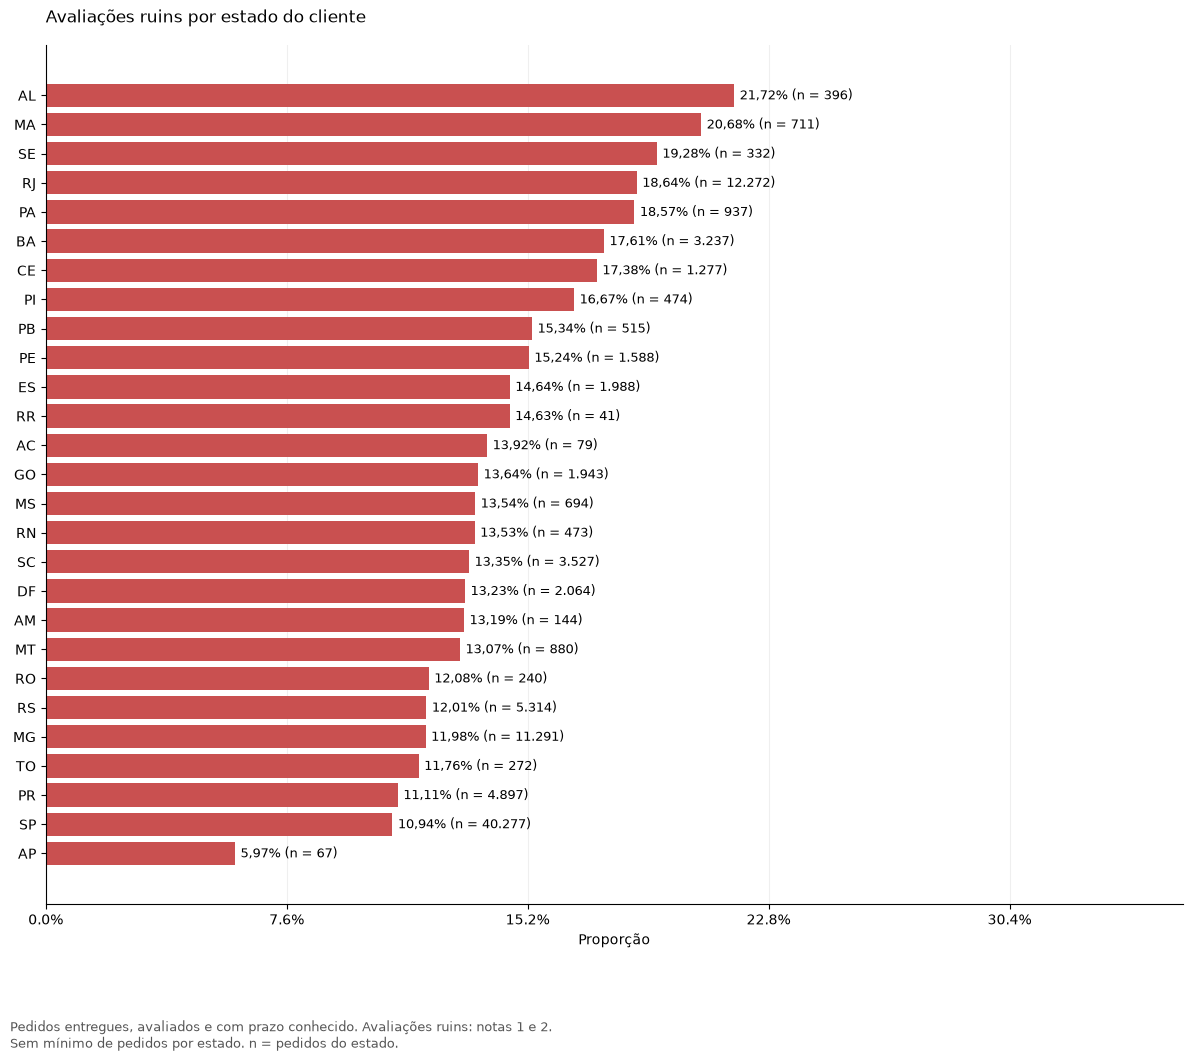

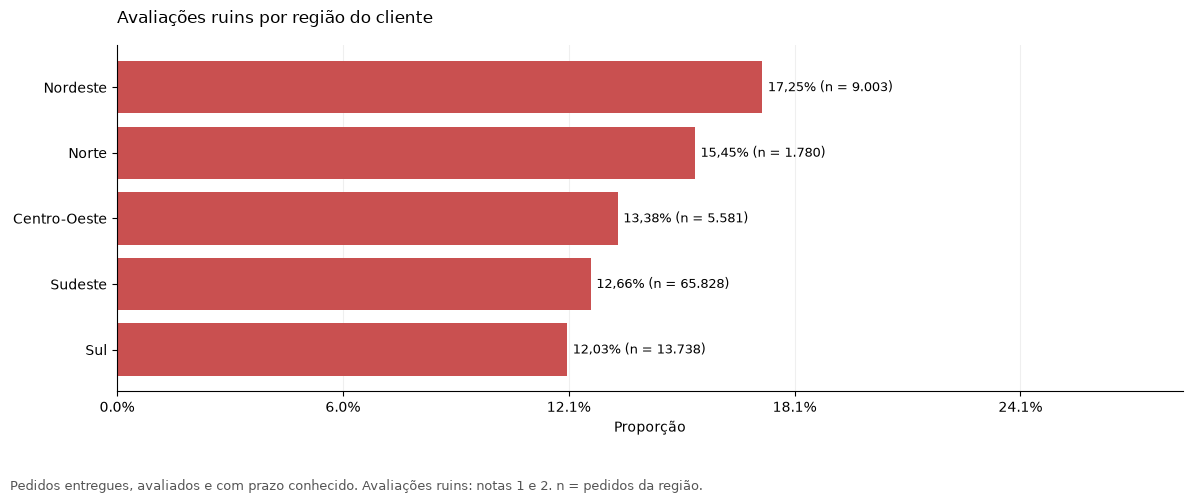

In [10]:
barras_taxas(
    df_ranking_estados, 'customer_state', 'pct_reviews_ruins', 'quantidade_pedidos',
    'Avaliações ruins por estado do cliente', '04_regioes_estados.png',
    'Pedidos entregues, avaliados e com prazo conhecido. Avaliações ruins: notas 1 e 2.\n'
    'Sem mínimo de pedidos por estado. n = pedidos do estado.'
)
df_grafico_regioes = df_ranking_regioes.copy()
df_grafico_regioes['nome_regiao'] = df_grafico_regioes['regiao'].str.replace('_', '-').str.title()
barras_taxas(
    df_grafico_regioes, 'nome_regiao', 'pct_reviews_ruins', 'quantidade_pedidos',
    'Avaliações ruins por região do cliente', '04_regioes_ranking.png',
    'Pedidos entregues, avaliados e com prazo conhecido. Avaliações ruins: notas 1 e 2. n = pedidos da região.'
)


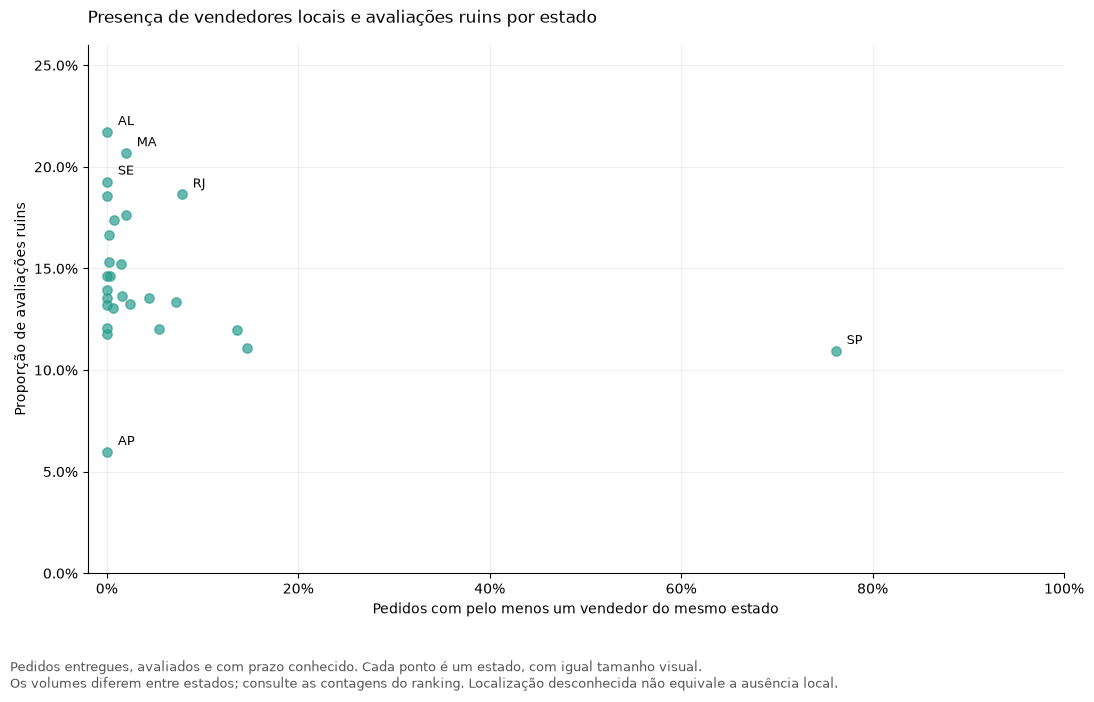

In [11]:
dados = df_ranking_estados.dropna(subset=['pct_pedidos_com_vendedor_local', 'pct_reviews_ruins'])
fig, ax = plt.subplots(figsize=(11, 7))
ax.scatter(dados['pct_pedidos_com_vendedor_local'].astype(float),
           dados['pct_reviews_ruins'].astype(float), color='#2A9D8F', s=45, alpha=0.7)
# Destaca os estados discutidos nas conclusões; todos continuam como pontos.
for _, linha in dados.loc[dados['customer_state'].isin(['AL', 'MA', 'SE', 'RJ', 'SP', 'AP'])].iterrows():
    ax.annotate(linha['customer_state'],
                (float(linha['pct_pedidos_com_vendedor_local']), float(linha['pct_reviews_ruins'])),
                xytext=(8, 5), textcoords='offset points', fontsize=9)
ax.set(xlabel='Pedidos com pelo menos um vendedor do mesmo estado',
       ylabel='Proporção de avaliações ruins', xlim=(-0.02, 1), ylim=(0, 0.26))
ax.set_title('Presença de vendedores locais e avaliações ruins por estado', loc='left', pad=16)
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.grid(alpha=0.2)
ax.set_axisbelow(True)
ax.spines[['top', 'right']].set_visible(False)
salvar_grafico(fig, '04_regioes_vendedores_locais.png',
    'Pedidos entregues, avaliados e com prazo conhecido. Cada ponto é um estado, com igual tamanho visual.\n'
    'Os volumes diferem entre estados; consulte as contagens do ranking. Localização desconhecida não equivale a ausência local.')


## Exportações

Salva as tabelas em Parquet e CSV e os gráficos em PNG.

In [12]:
PASTA_PARQUET = RAIZ_PROJETO / 'outputs' / 'tabelas' / 'parquet'
PASTA_CSV = RAIZ_PROJETO / 'outputs' / 'tabelas' / 'csv'
for pasta in (PASTA_PARQUET, PASTA_CSV, PASTA_GRAFICOS):
    pasta.mkdir(parents=True, exist_ok=True)

tabelas_exportar = {
    '04_ranking_estados': df_ranking_estados,
    '04_ranking_regioes': df_ranking_regioes,
}
for nome, original in tabelas_exportar.items():
    tabela = original.reset_index(drop=True).convert_dtypes()
    caminho = PASTA_PARQUET / f'{nome}.parquet'
    tabela.to_parquet(caminho, index=False)
    pd.testing.assert_frame_equal(tabela, pd.read_parquet(caminho), check_exact=True)
    tabela.to_csv(
        PASTA_CSV / f'{nome}.csv', index=False,
        sep=';', decimal=',', encoding='utf-8-sig'
    )
    print(f'Tabela exportada em Parquet e CSV: {nome} ({len(tabela)} linhas)')

for nome, conteudo in graficos_exportar.items():
    (PASTA_GRAFICOS / nome).write_bytes(conteudo)
    print(f'Gráfico exportado: {nome}')


Tabela exportada em Parquet e CSV: 04_ranking_estados (27 linhas)
Tabela exportada em Parquet e CSV: 04_ranking_regioes (5 linhas)
Gráfico exportado: 04_regioes_estados.png
Gráfico exportado: 04_regioes_ranking.png
Gráfico exportado: 04_regioes_vendedores_locais.png
